# 常规的条形图

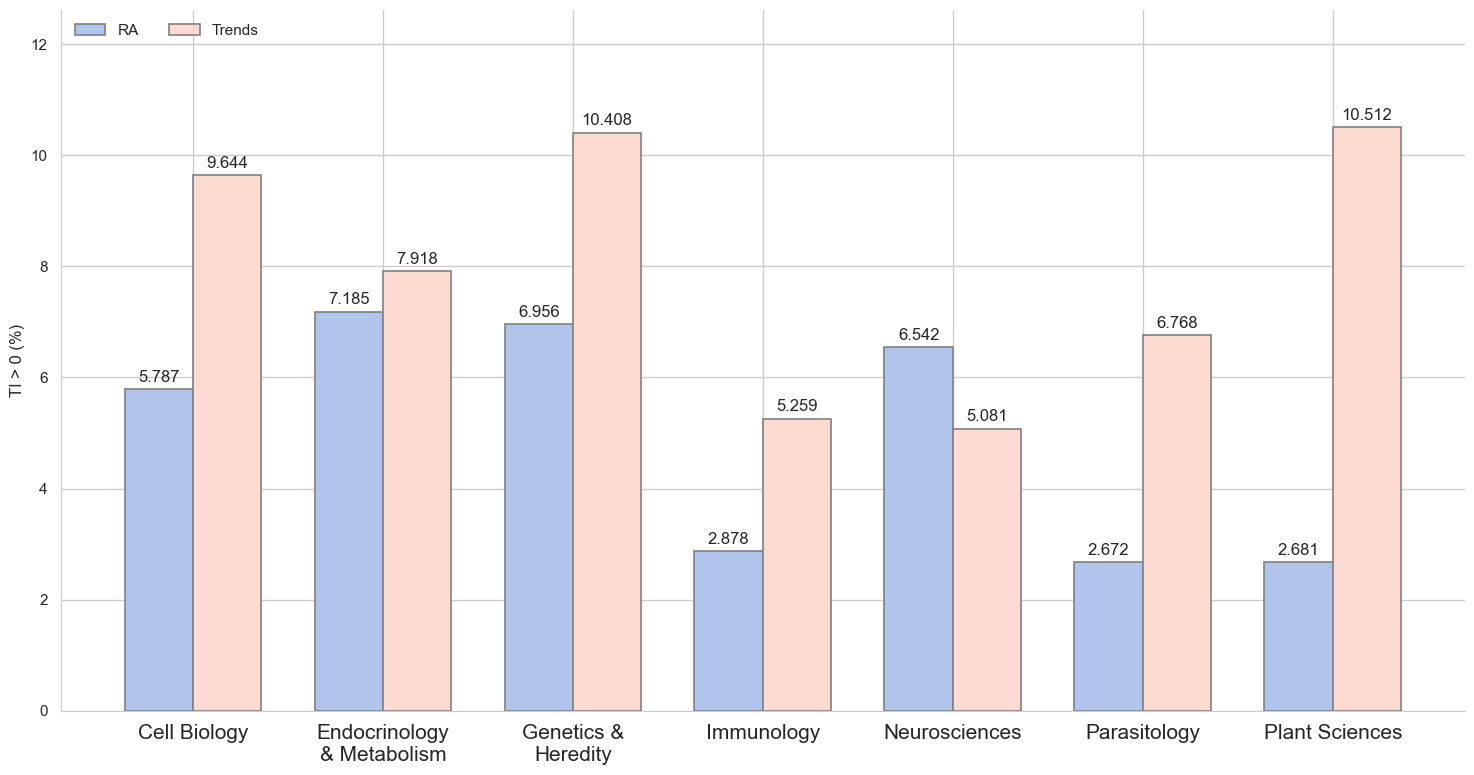

In [6]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np


categories = [
    "Cell Biology",
    "Endocrinology\n& Metabolism",
    "Genetics &\nHeredity",
    "Immunology",
    "Neurosciences",
    "Parasitology",
    "Plant Sciences",
]

ra = [5.787, 7.185, 6.956, 2.878, 6.542, 2.672, 2.681]
trends = [9.644, 7.918, 10.408, 5.259, 5.081, 6.768, 10.512]

# 字体与导出设置
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "DejaVu Sans"],
    "font.size": 15,
    "axes.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "pdf.fonttype": 42,
    "svg.fonttype": "none",
})

x = np.arange(len(categories))
width = 0.36

fig, ax = plt.subplots(figsize=(15, 8))

# 分组柱状图
bars_ra = ax.bar(
    x - width / 2, ra, width,
    label="RA", 
    color="#B1C4EB",
    edgecolor="#808080",
    linewidth=1.2
)
bars_trends = ax.bar(
    x + width / 2, trends, width,
    label="Trends", 
    color="#FEDBD0",
    edgecolor="#808080",
    linewidth=1.2
)

# 柱顶数值
ax.bar_label(bars_ra, fmt="%.3f", padding=3, fontsize=12)
ax.bar_label(bars_trends, fmt="%.3f", padding=3, fontsize=12)

# 坐标轴与图例
ax.set_xticks(x)
ax.set_xticklabels(categories, fontsize=15)
# ax.set_xlabel("WOS Category")
ax.set_ylabel("TI > 0 (%)")
ax.set_ylim(0, max(ra + trends) * 1.20)
ax.set_yticks(np.arange(0, 13, 2))
ax.legend(loc="upper left", ncol=2, frameon=False)

fig.tight_layout()

# 保存到脚本所在文件夹；Notebook 中则保存到当前目录
# output_dir = (
#     Path(__file__).resolve().parent
#     if "__file__" in globals()
#     else Path.cwd()
# )
# fig.savefig(output_dir / "bar_chart.png", dpi=600, bbox_inches="tight")
# fig.savefig(output_dir / "bar_chart.pdf", bbox_inches="tight")
# fig.savefig(output_dir / "bar_chart.svg", bbox_inches="tight")

plt.show()

# 横向条形图

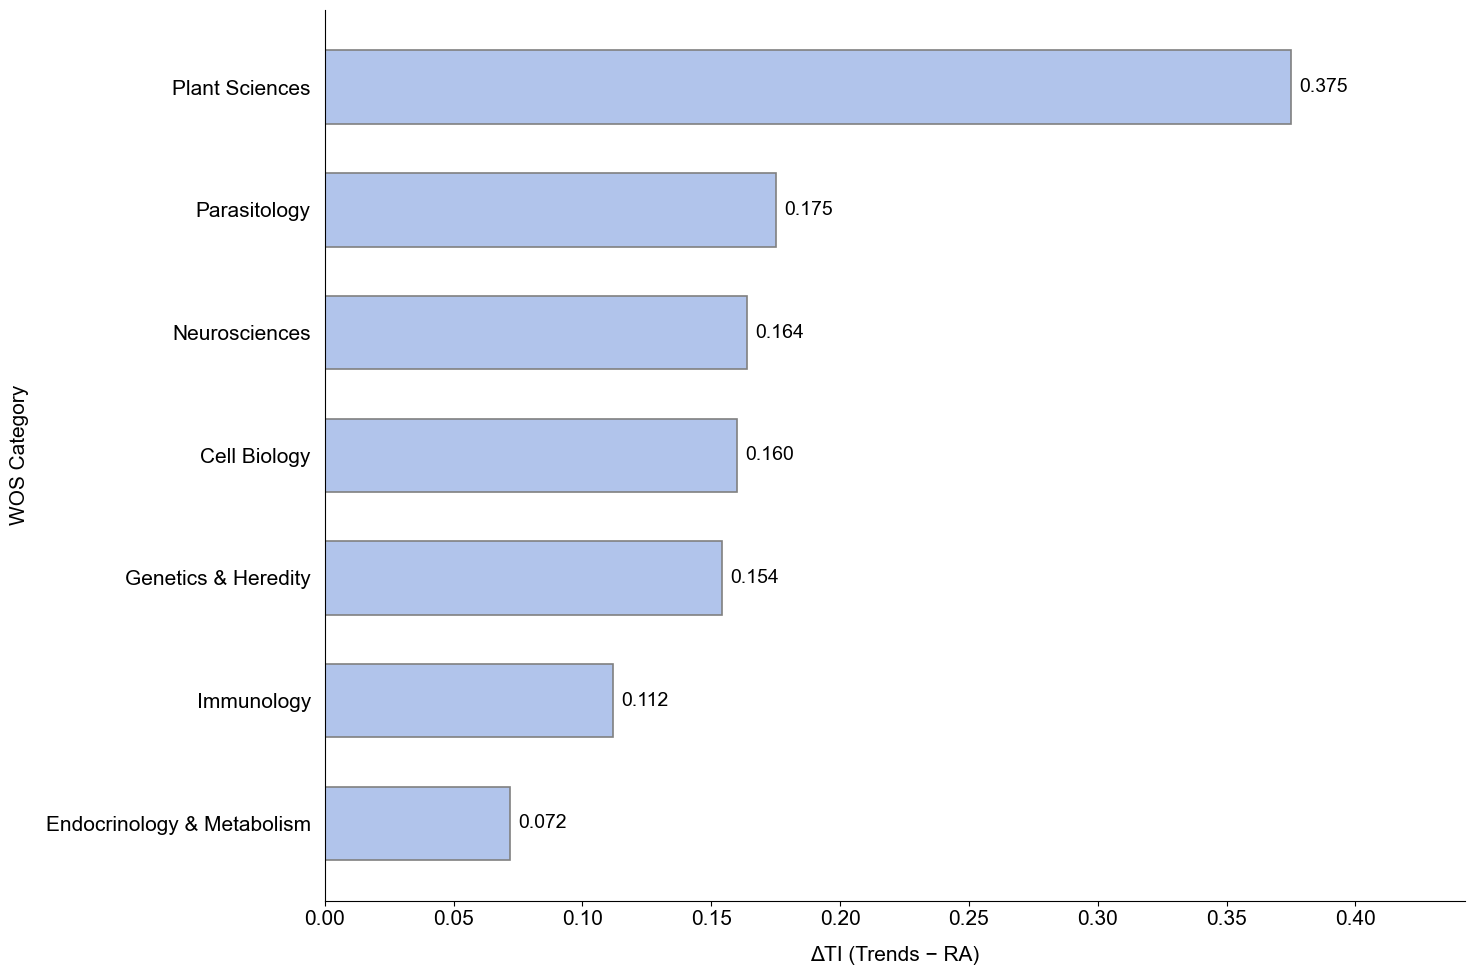

In [3]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import MultipleLocator, FormatStrFormatter

# 原始数据
categories = np.array([
    "Cell Biology",
    "Endocrinology & Metabolism",
    "Genetics & Heredity",
    "Immunology",
    "Neurosciences",
    "Parasitology",
    "Plant Sciences",
])

ra = np.array([
    -0.295, -0.254, -0.233, -0.270,
    -0.212, -0.454, -0.389
])

trends = np.array([
    -0.135, -0.182, -0.079, -0.158,
    -0.048, -0.279, -0.014
])

# 计算差值，并按差值从大到小排序
delta = trends - ra
order = np.argsort(-delta)

sorted_categories = categories[order]
sorted_delta = delta[order]

# 字体与导出设置
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "DejaVu Sans"],
    "font.size": 15,
    "axes.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "pdf.fonttype": 42,
    "svg.fonttype": "none",
})

fig, ax = plt.subplots(figsize=(15, 10))
y = np.arange(len(sorted_categories))

# 横向差值条形图
bars = ax.barh(
    y,
    sorted_delta,
    height=0.60,
    color="#B1C4EB",
    edgecolor="#808080",
    linewidth=1.2
)

# 条形末端标注三位小数
ax.bar_label(
    bars,
    fmt="%.3f",
    padding=6,
    fontsize=14
)

# 学科标签，最大差值位于最上方
ax.set_yticks(y)
ax.set_yticklabels(sorted_categories)
ax.invert_yaxis()

# 坐标轴：差值从 0 开始，右侧为数值标签留白
ax.set_xlabel("ΔTI (Trends − RA)", labelpad=12)
ax.set_ylabel("WOS Category", labelpad=12)
ax.set_xlim(0, sorted_delta.max() * 1.18)
ax.xaxis.set_major_locator(MultipleLocator(0.05))
ax.xaxis.set_major_formatter(FormatStrFormatter("%.2f"))
ax.tick_params(axis="y", length=0, pad=10)

fig.tight_layout()

# 如需保存图片，取消下面几行的注释
# output_dir = (
#     Path(__file__).resolve().parent
#     if "__file__" in globals()
#     else Path.cwd()
# )
# fig.savefig(output_dir / "ti_difference.png", dpi=600)
# fig.savefig(output_dir / "ti_difference.pdf")
# fig.savefig(output_dir / "ti_difference.svg")

plt.show()

# 组件消融条形图

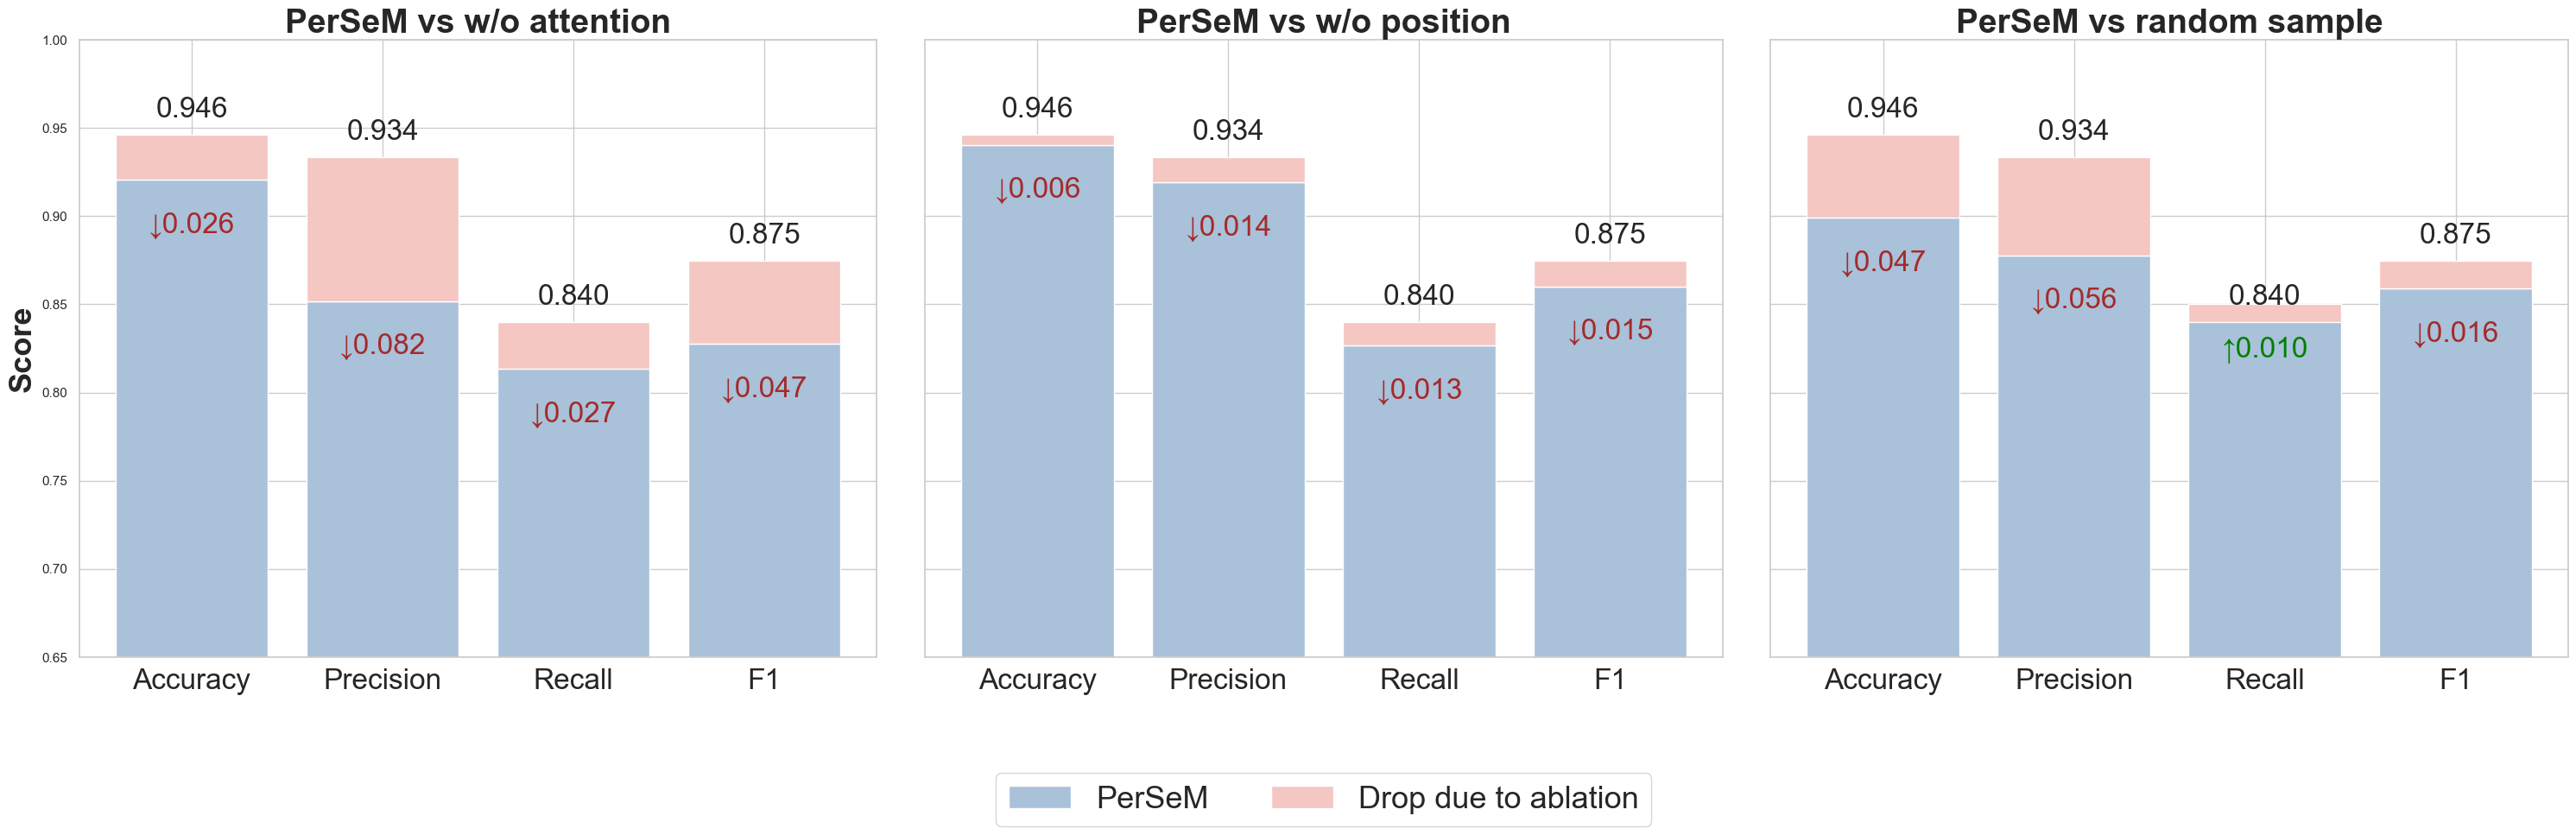

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import matplotlib

# 删除或注释这一行，否则图像不会显示在notebook中
# matplotlib.use('Agg')

# =================== 修改：统一设置字体大小和样式（放大版本） ===================
matplotlib.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Arial', 'Helvetica'],
    'font.size': 24,          # 从8放大到24
    'axes.labelsize': 26,     # 从9放大到26
    'axes.titlesize': 28,     # 从10放大到28
    'legend.fontsize': 30,    # 从8放大到24
    'xtick.labelsize': 28,    # 从8放大到24
    'ytick.labelsize': 28,    # 从8放大到24
})
# ============================================================

# 指标名称
metrics = ['Accuracy', 'Precision', 'Recall', 'F1']
csot_scores = np.array([0.9464, 0.9336, 0.8401, 0.8749])

# 各消融组得分
ablation_groups = {
    'w/o attention': np.array([0.9206, 0.8518, 0.8135, 0.8276]),
    'w/o position': np.array([0.9404, 0.9191, 0.8266, 0.8601]),
    'random sample': np.array([0.8990, 0.8778, 0.8501, 0.8590])
}

# 图形设置
sns.set(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(30, 10))  # 增大图像尺寸

# 颜色配置（低饱和度）
csot_color = '#a9c1d9'  # 灰蓝
drop_color = '#f4c7c3'  # 淡粉

# 绘制每个子图
fig_id = 0
for ax, (title, ablation_score) in zip(axes.flat, ablation_groups.items()):
    drop = csot_scores - ablation_score

    # 绘制柱状图：底层为 ablation，叠加为下降部分
    ax.bar(metrics, ablation_score, color=csot_color, label='PerSeM')
    ax.bar(metrics, drop, bottom=ablation_score, color=drop_color, label='Drop due to ablation')

    # 添加文本注释
    for i in range(len(metrics)):
        ax.text(i, csot_scores[i] + 0.01, f"{csot_scores[i]:.3f}", ha='center', fontsize=24)
        # 根据drop的正负来决定箭头方向和颜色
        if drop[i] >= 0:
            arrow_text = f"↓{drop[i]:.3f}"
            color = 'brown'
        else:
            arrow_text = f"↑{abs(drop[i]):.3f}"
            color = 'green'
        ax.text(i, ablation_score[i] - 0.03, arrow_text, ha='center', color=color, fontsize=24)

    # 设置图形参数
    ax.set_title(f"PerSeM vs {title}", fontsize=28, fontweight='bold')
    ax.set_ylim(0.65, 1)
    if fig_id == 0:
        ax.set_ylabel("Score", fontsize=26, fontweight='bold')
    else:
        ax.set_yticks(np.arange(0.65, 0.95, 0.05))
        ax.set_yticklabels([])
    ax.set_xticks(range(len(metrics)))
    ax.set_xticklabels(metrics, fontsize=24)
    fig_id += 1

# 图例只放在中间图上
axes[1].legend(loc='lower center', bbox_to_anchor=(0.5, -0.3), ncol=2, fontsize=26)

plt.tight_layout()
plt.subplots_adjust(hspace=0.1)

# 保存为 PDF
# plt.savefig("ablation.V4.pdf", bbox_inches='tight')

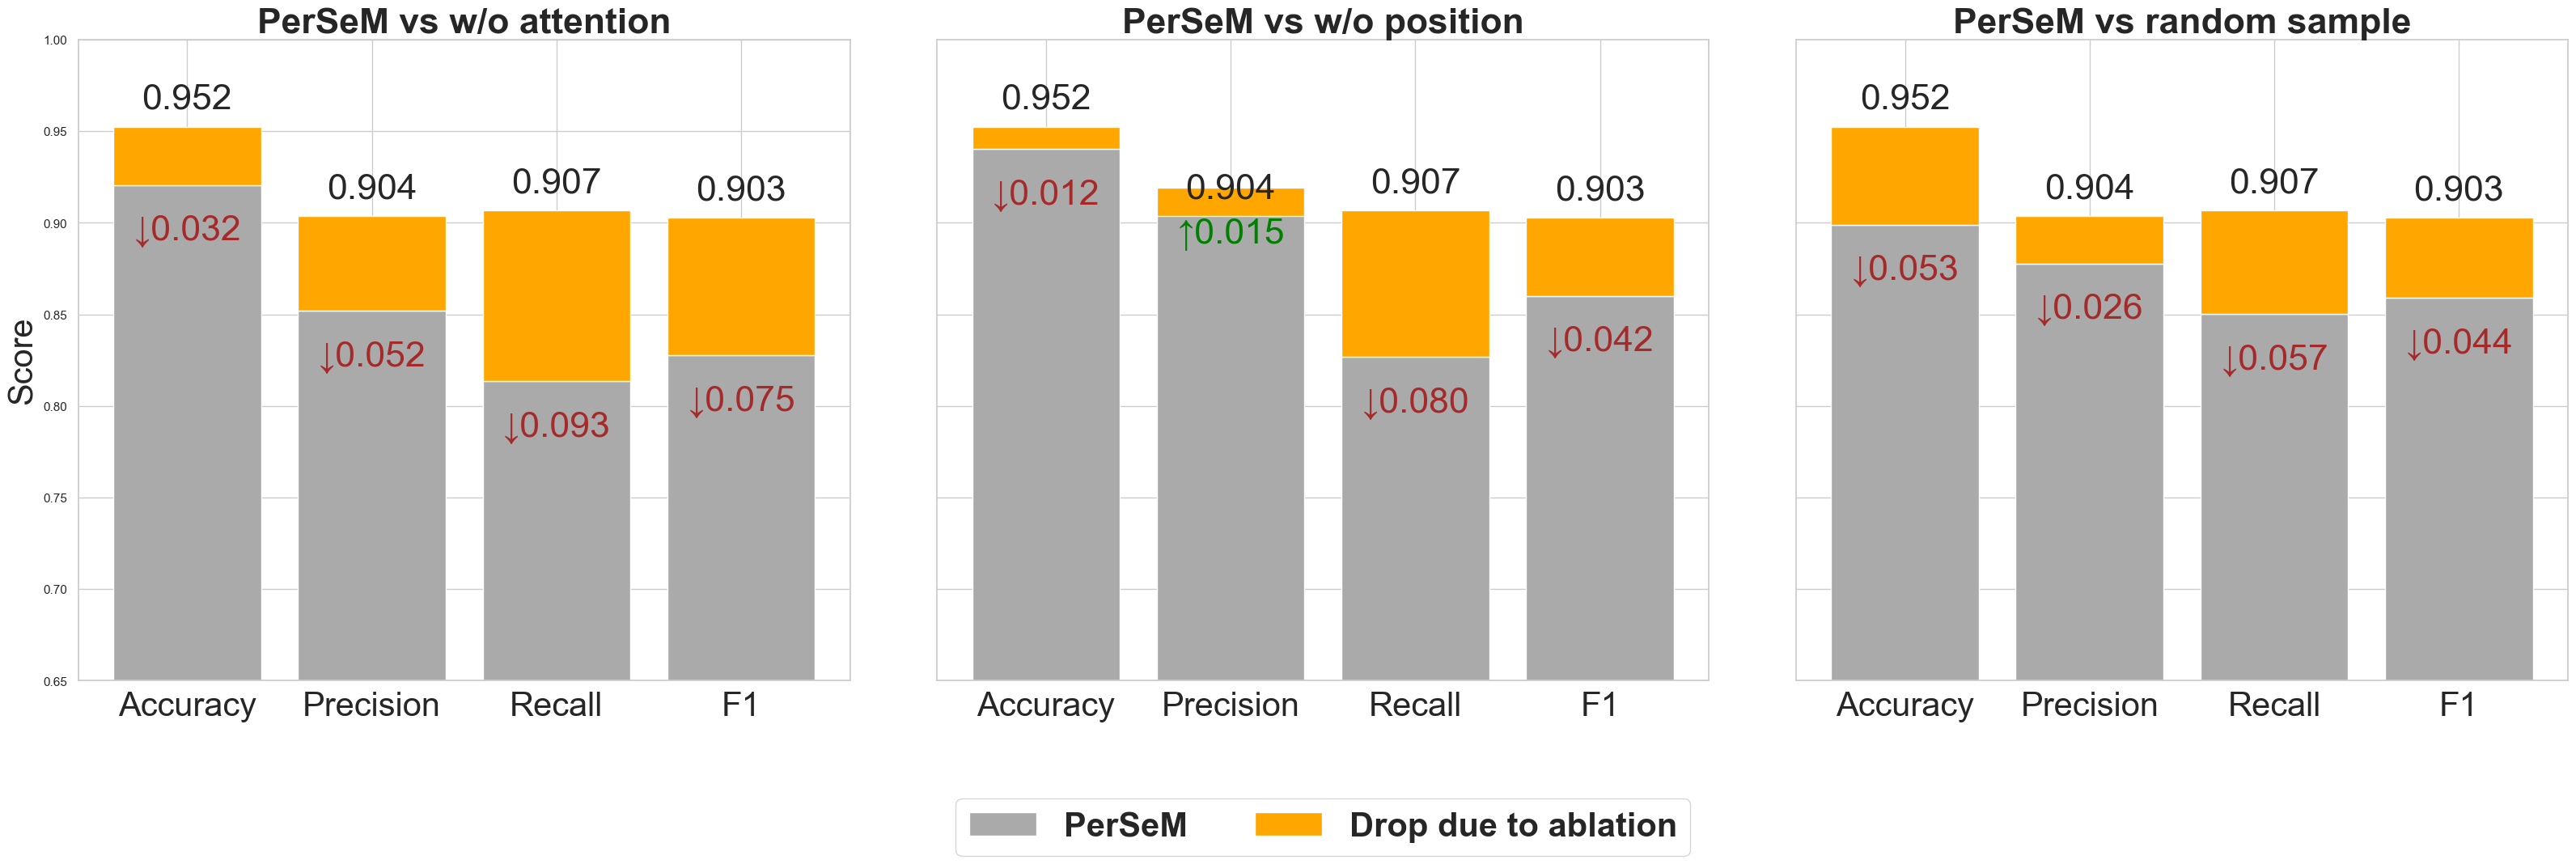

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import matplotlib

# 删除或注释这一行，否则图像不会显示在notebook中
# matplotlib.use('Agg')

# =================== 修改：统一设置字体大小和样式（放大版本） ===================
matplotlib.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Arial', 'Helvetica'],
    'font.size': 24,          
    'axes.labelsize': 26,     
    'axes.titlesize': 28,     
    'legend.fontsize': 30,    
    'xtick.labelsize': 28,    
    'ytick.labelsize': 28,    
    'figure.titlesize': 32,   # 添加图形标题字体大小
})
# ============================================================

# 指标名称
metrics = ['Accuracy', 'Precision', 'Recall', 'F1']
csot_scores = np.array([0.9524, 0.9037, 0.9067, 0.9026])

# 各消融组得分
ablation_groups = {
    'w/o attention': np.array([0.9206, 0.8518, 0.8135, 0.8276]),
    'w/o position': np.array([0.9404, 0.9191, 0.8266, 0.8601]),
    'random sample': np.array([0.8990, 0.8778, 0.8501, 0.8590])
}

# 图形设置
sns.set(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(32, 10))  # 增大图像尺寸

# 颜色配置（低饱和度）
csot_color = '#aaaaab'  # 灰蓝
drop_color = '#ffa600'  # 淡粉

# 绘制每个子图
fig_id = 0
for ax, (title, ablation_score) in zip(axes.flat, ablation_groups.items()):
    drop = csot_scores - ablation_score

    # 绘制柱状图：底层为 ablation，叠加为下降部分
    bars1 = ax.bar(metrics, ablation_score, color=csot_color, label='PerSeM')
    bars2 = ax.bar(metrics, drop, bottom=ablation_score, color=drop_color, label='Drop due to ablation')

    # 添加文本注释 - 使用更大的字体
    for i in range(len(metrics)):
        # CSOT 总分标注
        ax.text(i, csot_scores[i] + 0.01, f"{csot_scores[i]:.3f}", 
                ha='center', fontsize=32)  # 增大字体到32
        # 差值标注
        if drop[i] >= 0:
            arrow_text = f"↓{drop[i]:.3f}"
            color = 'brown'
        else:
            arrow_text = f"↑{abs(drop[i]):.3f}"
            color = 'green'
        ax.text(i, ablation_score[i] - 0.03, arrow_text, 
                ha='center', color=color, fontsize=32)  # 增大字体到32

    # 设置图形参数
    ax.set_title(f"PerSeM vs {title}", fontsize=32, fontweight='bold')  # 增大标题字体
    ax.set_ylim(0.65, 1)
    if fig_id == 0:
        ax.set_ylabel("Score", fontsize=30)  # 增大y轴标签字体
    else:
        ax.set_yticks(np.arange(0.65, 0.95, 0.05))
        ax.set_yticklabels([])
    ax.set_xticks(range(len(metrics)))
    ax.set_xticklabels(metrics, fontsize=30)  # 增大x轴标签字体
    fig_id += 1

# 图例设置 - 确保字体大小
legend = axes[1].legend(loc='lower center', bbox_to_anchor=(0.5, -0.3), 
                       ncol=2, fontsize=30,  # 确保图例字体大小
                       prop={'size': 30, 'weight': 'bold'})  # 显式设置字体属性

plt.tight_layout()
plt.subplots_adjust(hspace=0.1, bottom=0.15)  # 为图例留出更多空间

# 保存为 PDF
# plt.savefig("ablation.V5.pdf", bbox_inches='tight', dpi=300)  # 添加高DPI

plt.show()  # 显示图形

# 堆叠柱状图

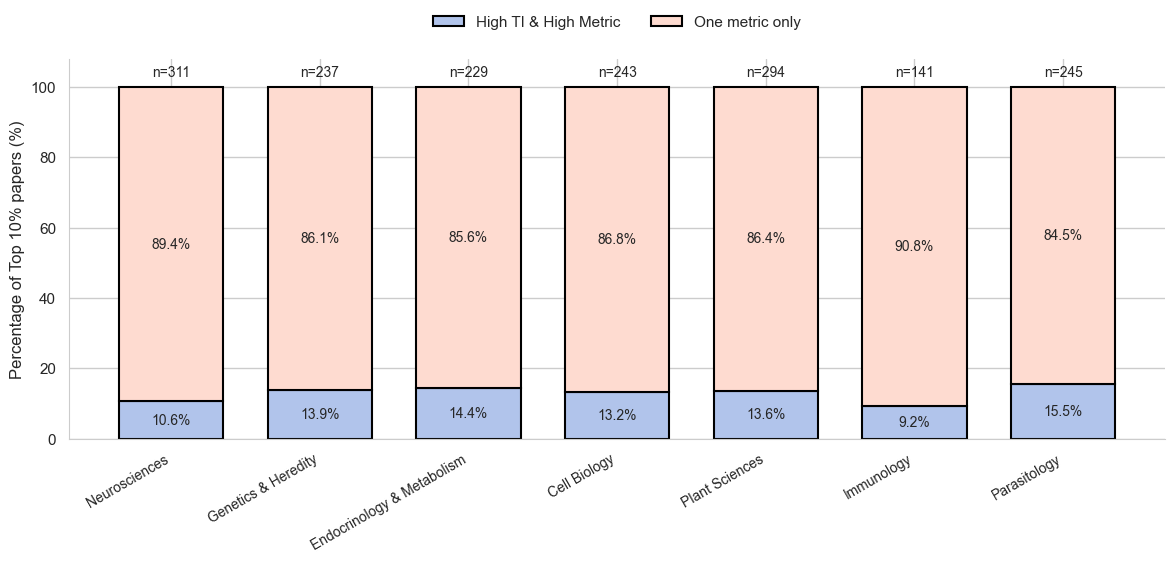

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# =========================
# 1. 数据
# =========================
data = {
    "WoS field": [
        "Neurosciences",
        "Genetics & Heredity",
        "Endocrinology & Metabolism",
        "Cell Biology",
        "Plant Sciences",
        "Immunology",
        "Parasitology"
    ],
    "Top10": [311, 237, 229, 243, 294, 141, 245],
    "Both":  [33, 33, 33, 32, 40, 13, 38],
    "One_only": [278, 204, 196, 211, 254, 128, 207]
}

df = pd.DataFrame(data)

# =========================
# 2. 转换为比例
# =========================
df["Both_pct"] = df["Both"] / df["Top10"] * 100
df["One_pct"] = df["One_only"] / df["Top10"] * 100

# =========================
# 3. 配色
# =========================
# 颜色取自你提供的色板
color_both = "#B1C4EB"    # 深一点的蓝色：重点
color_one  = "#FEDBD0"    # 浅粉色：只进入一个指标
color_edge = "black"
color_bg   = "#EBF3F7"    # 浅背景色

# =========================
# 4. 绘图
# =========================
fig, ax = plt.subplots(figsize=(12, 6))

x = np.arange(len(df))
width = 0.7

# High TI & High Metric
ax.bar(
    x,
    df["Both_pct"],
    width=width,
    color=color_both,
    edgecolor=color_edge,
    linewidth=1.5,
    label="High TI & High Metric"
)

# One metric only
ax.bar(
    x,
    df["One_pct"],
    width=width,
    bottom=df["Both_pct"],
    color=color_one,
    edgecolor=color_edge,
    linewidth=1.5,
    label="One metric only"
)

# =========================
# 5. 在柱子内部标注比例
# =========================
for i in range(len(df)):

    # 双高比例
    ax.text(
        x[i],
        df.loc[i, "Both_pct"] / 2,
        f'{df.loc[i, "Both_pct"]:.1f}%',
        ha="center",
        va="center",
        fontsize=10
    )

    # 单指标比例
    ax.text(
        x[i],
        df.loc[i, "Both_pct"] + df.loc[i, "One_pct"] / 2,
        f'{df.loc[i, "One_pct"]:.1f}%',
        ha="center",
        va="center",
        fontsize=10
    )

    # 柱顶标注 Top10% 实际数量
    ax.text(
        x[i],
        102,
        f'n={df.loc[i, "Top10"]}',
        ha="center",
        va="bottom",
        fontsize=10
    )

# =========================
# 6. 图形美化
# =========================
ax.set_ylim(0, 108)

ax.set_ylabel("Percentage of Top 10% papers (%)", fontsize=12)

ax.set_xticks(x)
ax.set_xticklabels(
    df["WoS field"],
    rotation=30,
    ha="right",
    fontsize=10
)

ax.set_yticks([0, 20, 40, 60, 80, 100])

ax.legend(
    frameon=False,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.15),
    ncol=2
)

# 去掉上、右边框
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

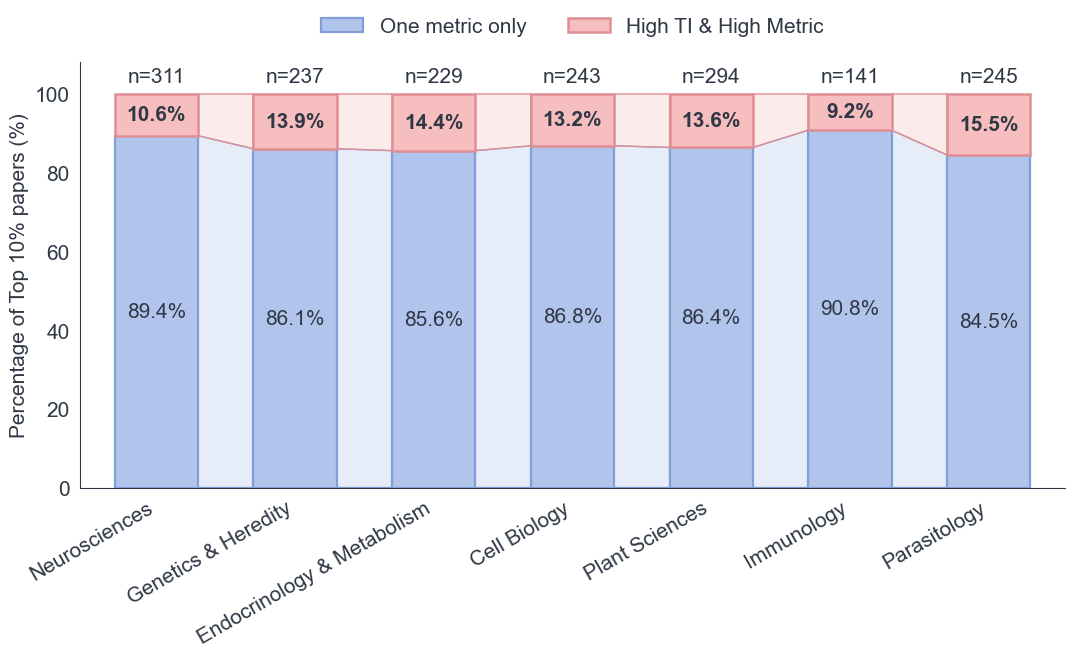

In [8]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np
from matplotlib.patches import Polygon

# ==================== 全局参数 ====================
FONT_SIZE = 15

# ==================== 字体与导出设置 ====================
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "DejaVu Sans"],
    "font.size": FONT_SIZE,
    "text.color": "#303846",
    "axes.labelcolor": "#303846",
    "xtick.color": "#303846",
    "ytick.color": "#303846",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.grid": False,
    "pdf.fonttype": 42,
    "svg.fonttype": "none",
})


# ==================== 1. 数据 ====================
data = {
    "WoS field": [
        "Neurosciences",
        "Genetics & Heredity",
        "Endocrinology & Metabolism",
        "Cell Biology",
        "Plant Sciences",
        "Immunology",
        "Parasitology"
    ],

    "Top10": [
        311, 237, 229, 243, 294, 141, 245
    ],

    # 红色顶部：重点关注
    "Both": [
        33, 33, 33, 32, 40, 13, 38
    ],

    # 蓝色底部
    "One_only": [
        278, 204, 196, 211, 254, 128, 207
    ]
}

df = pd.DataFrame(data)


# ==================== 2. 转换为比例 ====================
df["Both_pct"] = df["Both"] / df["Top10"] * 100
df["One_pct"] = df["One_only"] / df["Top10"] * 100


# ==================== 3. 配色 ====================

# 蓝色：底部 One metric only
color_blue = "#B1C4EB"
edge_blue = "#7F9FD6"

# 红色：顶部 High TI & High Metric
color_red = "#F7BEBF"
edge_red = "#DF8F94"

# ribbon 填充透明度
RIBBON_ALPHA = 0.3


# ==================== 4. 建立画布 ====================
fig, ax = plt.subplots(figsize=(11, 7))

x = np.arange(len(df))

# 柱宽
width = 0.6


# ==========================================================
# 5. 相邻柱子之间的连接带 Ribbon
#    注意：先画连接带，再画柱子
# ==========================================================

for i in range(len(df) - 1):

    # 当前柱右边缘
    x1 = x[i] + width / 2

    # 下一根柱左边缘
    x2 = x[i + 1] - width / 2

    # 当前、下一根柱子的蓝色区域高度
    blue_y1 = df.loc[i, "One_pct"]
    blue_y2 = df.loc[i + 1, "One_pct"]


    # --------------------------
    # 蓝色连接区域
    # --------------------------
    blue_vertices = [
        (x1, 0),
        (x2, 0),
        (x2, blue_y2),
        (x1, blue_y1)
    ]

    blue_ribbon = Polygon(
        blue_vertices,
        closed=True,
        facecolor=mcolors.to_rgba(
            color_blue,
            RIBBON_ALPHA
        ),
        edgecolor=edge_blue,
        linewidth=1.0,
        zorder=1
    )

    ax.add_patch(blue_ribbon)


    # --------------------------
    # 红色连接区域
    # --------------------------
    red_vertices = [
        (x1, blue_y1),
        (x2, blue_y2),
        (x2, 100),
        (x1, 100)
    ]

    red_ribbon = Polygon(
        red_vertices,
        closed=True,
        facecolor=mcolors.to_rgba(
            color_red,
            RIBBON_ALPHA
        ),
        edgecolor=edge_red,
        linewidth=1.0,
        zorder=1
    )

    ax.add_patch(red_ribbon)


# ==========================================================
# 6. 正式绘制柱子
# ==========================================================

# --------------------------
# 底部：蓝色
# One metric only
# --------------------------
ax.bar(
    x,
    df["One_pct"],
    width=width,
    color=color_blue,
    edgecolor=edge_blue,
    linewidth=1.6,
    label="One metric only",
    zorder=3
)


# --------------------------
# 顶部：红色
# High TI & High Metric
# --------------------------
ax.bar(
    x,
    df["Both_pct"],
    width=width,
    bottom=df["One_pct"],
    color=color_red,
    edgecolor=edge_red,
    linewidth=1.8,
    label="High TI & High Metric",
    zorder=3
)


# ==========================================================
# 7. 数值标注
# ==========================================================

for i in range(len(df)):

    # --------------------------
    # 蓝色部分比例
    # --------------------------
    ax.text(
        x[i],
        df.loc[i, "One_pct"] / 2,

        f'{df.loc[i, "One_pct"]:.1f}%',

        ha="center",
        va="center",

        fontsize=FONT_SIZE,
        color="#303846",

        zorder=5
    )


    # --------------------------
    # 红色 Both 比例
    # --------------------------
    ax.text(
        x[i],

        df.loc[i, "One_pct"]
        + df.loc[i, "Both_pct"] / 2,

        f'{df.loc[i, "Both_pct"]:.1f}%',

        ha="center",
        va="center",

        fontsize=FONT_SIZE,
        fontweight="bold",
        color="#303846",

        zorder=5
    )


    # --------------------------
    # Top10% 总量
    # --------------------------
    ax.text(
        x[i],
        102,

        f'n={df.loc[i, "Top10"]}',

        ha="center",
        va="bottom",

        fontsize=FONT_SIZE,
        color="#303846",

        zorder=5
    )


# ==========================================================
# 8. 坐标轴
# ==========================================================

ax.set_ylim(0, 108)

# 左右留一点空间
ax.set_xlim(
    -0.55,
    len(df) - 0.45
)

ax.set_ylabel(
    "Percentage of Top 10% papers (%)",
    fontsize=FONT_SIZE
)

ax.set_xticks(x)

ax.set_xticklabels(
    df["WoS field"],
    rotation=30,
    ha="right",
    fontsize=FONT_SIZE
)

ax.set_yticks(
    [0, 20, 40, 60, 80, 100]
)

ax.tick_params(
    axis="both",
    labelsize=FONT_SIZE,
    length=4,
    width=0.8
)


# ==========================================================
# 9. 图例
# ==========================================================

ax.legend(
    frameon=False,

    loc="upper center",
    bbox_to_anchor=(0.5, 1.15),

    ncol=2,

    fontsize=FONT_SIZE
)


# ==========================================================
# 10. 边框
# ==========================================================

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.spines["left"].set_color("#303846")
ax.spines["bottom"].set_color("#303846")

ax.spines["left"].set_linewidth(0.8)
ax.spines["bottom"].set_linewidth(0.8)



# ==========================================================
# 11. 布局
# ==========================================================

plt.tight_layout()

# ==================== 可选保存 ====================
# SAVE_FIGURE = True   # 改成 False 就不保存

# if SAVE_FIGURE:
#     output_dir = (
#         Path(__file__).resolve().parent
#         if "__file__" in globals()
#         else Path.cwd()
#     )

#     fig.savefig(output_dir / "top10_ribbon.png", dpi=600, bbox_inches="tight")
#     fig.savefig(output_dir / "top10_ribbon.pdf", bbox_inches="tight")
#     fig.savefig(output_dir / "top10_ribbon.svg", bbox_inches="tight")

plt.show()